# API Reliability and Latency Analysis

This notebook analyzes saved monitoring records and demonstrates statistical methods. **Real SQLite observations and synthetic fallback data are clearly distinguished.** Run from the repository root; no public API is called.

## 1. Problem statement, objectives, and research questions

The goal is to compare endpoint reliability and latency, describe observed distributions, test simple anomaly detectors, and compare sequential versus concurrent I/O. Questions: (1) how do success rates vary? (2) how skewed are latency distributions? (3) can known injected spikes be flagged? (4) does bounded concurrency reduce elapsed time for delayed I/O?

## 2. Technology overview and data dictionary

Python runs the experiment; SQLite persists runs; Pandas cleans and groups records; NumPy computes percentiles; Plotly visualizes. Core fields include `timestamp` (UTC attempt time), `endpoint_id`, `endpoint_name`, `response_time_ms` (measured duration, nullable), `status_code` (nullable without HTTP response), `success`, and `failure_category`. Synthetic fallback rows are marked with `synthetic=True`.

## 3. Environment setup and imports

In [12]:
from pathlib import Path
import sys, random, time
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import plotly.express as px
from src.database import query_logs
from src.analytics import records_frame, calculate_metrics, endpoint_metrics
from src.anomaly_detection import rolling_median_anomalies, iqr_anomalies
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)
print("Project root:", ROOT)


Project root: C:\Users\Thiru\Downloads\api-reliability-analyzer\api-reliability-analyzer


## 4. Load SQLite data or use an explicitly synthetic fallback

In [13]:
db_path = ROOT / "data" / "api_monitoring.db"
if not db_path.exists() and (ROOT / "data" / "experiments.db").exists():
    db_path = ROOT / "data" / "experiments.db"
records = query_logs(db_path) if db_path.exists() else []
if records:
    df = records_frame(records)
    df["synthetic"] = False
    data_source = "REAL local SQLite monitoring records"
else:
    rng = np.random.default_rng(RANDOM_SEED)
    now = pd.Timestamp.now(tz="UTC")
    rows = []
    for eid, name, mean in [(1, "Synthetic fast API", 45), (2, "Synthetic delayed API", 180), (3, "Synthetic variable API", 90)]:
        values = np.maximum(1, rng.normal(mean, mean * .18, 60))
        values[[17, 43]] *= 4
        for i, value in enumerate(values):
            success = bool(rng.random() > .08)
            rows.append({"timestamp": now - pd.Timedelta(minutes=180-i*3), "endpoint_id": eid,
                         "endpoint_name": name, "response_time_ms": float(value), "status_code": 200 if success else 500,
                         "success": success, "failure_category": None if success else "http_error", "synthetic": True})
    df = pd.DataFrame(rows)
    data_source = "SYNTHETIC fallback observations (not real API measurements)"
print(data_source, "| rows:", len(df))
df.head()


REAL local SQLite monitoring records | rows: 45


,id,run_id,endpoint_id,timestamp,method,response_time_ms,status_code,success,failure_category,error_message,response_size_bytes,execution_id,endpoint_name,endpoint_url,execution_mode,synthetic
0,45,33,2,2026-10-25 20:20:49.743+00:00,GET,641.0,200,True,None,None,2396,6956bf75-a299-4382-bc56-8ddc7262da48,2nd one,https://api.github.com,concurrent,False
1,44,33,1,2026-10-25 20:20:49.743+00:00,GET,625.0,200,True,None,None,292,6956bf75-a299-4382-bc56-8ddc7262da48,JSONPlaceholder Test,https://jsonplaceholder.typicode.com/posts/1,concurrent,False
2,43,32,2,2026-10-25 20:20:46.420+00:00,GET,625.0,200,True,None,None,2396,51a0d243-63f8-424f-9a82-7bf95068f1f6,2nd one,https://api.github.com,concurrent,False
3,42,32,1,2026-10-25 20:20:46.419+00:00,GET,547.0,200,True,None,None,292,51a0d243-63f8-424f-9a82-7bf95068f1f6,JSONPlaceholder Test,https://jsonplaceholder.typicode.com/posts/1,concurrent,False
4,41,31,2,2026-10-25 20:20:46.120+00:00,GET,688.0,200,True,None,None,2396,fc67f47d-9afb-4393-b804-eebd74f10b8a,2nd one,https://api.github.com,concurrent,False


## 5. Data cleaning and validation

In [14]:
if not df.empty:
    df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True, errors="coerce")
    df["response_time_ms"] = pd.to_numeric(df["response_time_ms"], errors="coerce")
    df["success"] = df["success"].fillna(False).astype(bool)
    df = df.dropna(subset=["timestamp"]).sort_values("timestamp").reset_index(drop=True)
    print("Missing latency values:", int(df["response_time_ms"].isna().sum()))
    print("Duplicate rows:", int(df.duplicated().sum()))
    display(df.describe(include="all").transpose())
else:
    print("No records available.")


Missing latency values: 0
Duplicate rows: 0


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
id,45.0,NaN,NaN,NaN,23.0,1.0,12.0,23.0,34.0,45.0,13.133926
run_id,45.0,NaN,NaN,NaN,19.8,1.0,12.0,22.0,28.0,33.0,9.659193
endpoint_id,45.0,NaN,NaN,NaN,1.266667,1.0,1.0,1.0,2.0,2.0,0.447214
timestamp,45,NaN,NaN,NaN,2026-10-25 20:09:33.241334+00:00,2026-10-25 19:55:22.845000+00:00,2026-10-25 19:56:54.894000+00:00,2026-10-25 20:20:40.325000+00:00,2026-10-25 20:20:45.291000+00:00,2026-10-25 20:20:49.743000+00:00,NaN
method,45,1,GET,45,NaN,NaN,NaN,NaN,NaN,NaN,NaN
response_time_ms,45.0,NaN,NaN,NaN,562.2,390.0,407.0,578.0,672.0,813.0,136.060414
status_code,45.0,NaN,NaN,NaN,200.0,200.0,200.0,200.0,200.0,200.0,0.0
success,45,1,True,45,NaN,NaN,NaN,NaN,NaN,NaN,NaN
failure_category,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
error_message,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 6. Exploratory analysis and descriptive statistics

,endpoint_id,endpoint_name,total_attempts,success_rate_pct,median_latency_ms,p95_latency_ms,failed_requests,timeout_count
0,1,JSONPlaceholder Test,33,100.0,469.0,715.4,0,0
1,2,2nd one,12,100.0,680.0,804.2,0,0


success,True,All
endpoint_name,,
2nd one,12,12
JSONPlaceholder Test,33,33
All,45,45


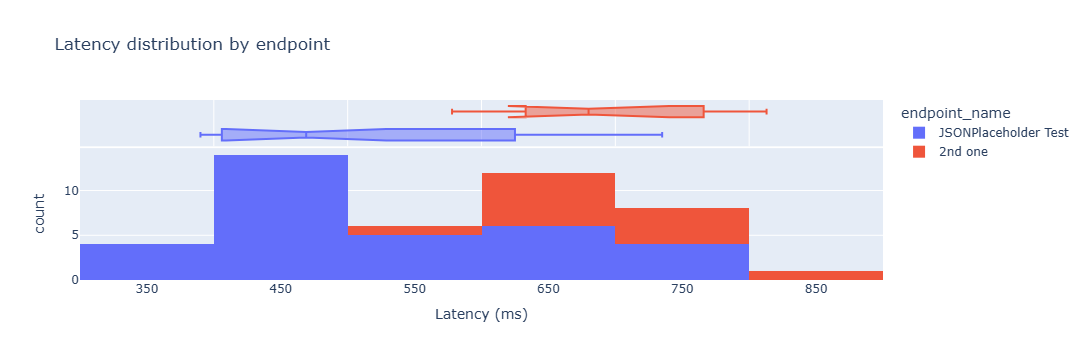

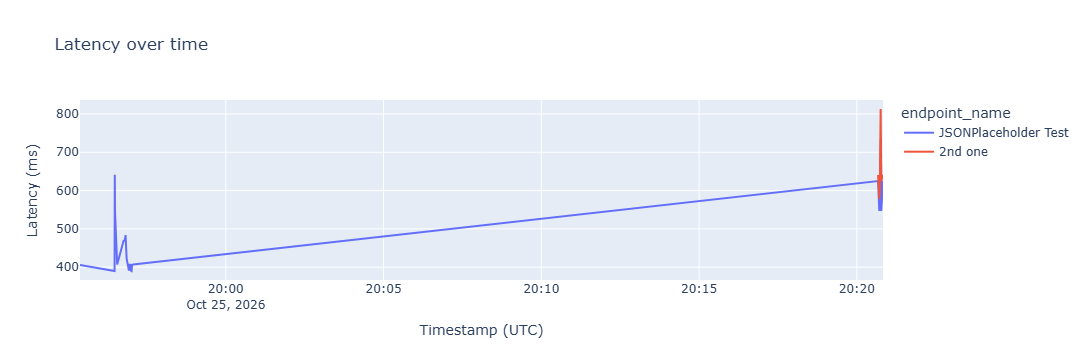

In [15]:
if not df.empty:
    display(endpoint_metrics(df))
    display(pd.crosstab(df["endpoint_name"], df["success"], margins=True))
    fig = px.histogram(df, x="response_time_ms", color="endpoint_name", marginal="box",
                       title="Latency distribution by endpoint", labels={"response_time_ms":"Latency (ms)"})
    fig.show()
    fig = px.line(df.sort_values("timestamp"), x="timestamp", y="response_time_ms", color="endpoint_name",
                  title="Latency over time", labels={"timestamp":"Timestamp (UTC)","response_time_ms":"Latency (ms)"})
    fig.show()
else:
    print("Exploration skipped: empty dataset.")


## 7. Reliability and latency metrics

In [16]:
if not df.empty:
    metric_rows=[]
    for name, group in df.groupby("endpoint_name"):
        m=calculate_metrics(group)
        metric_rows.append({"endpoint":name, **m})
    metrics_df=pd.DataFrame(metric_rows)
    display(metrics_df)
    print("Rates use all attempts. Latency summaries use only non-missing measured durations.")
    print("P95 uses NumPy's linear interpolation convention.")
else:
    print(calculate_metrics(df))


,endpoint,total_attempts,successful_requests,failed_requests,success_rate_pct,failure_rate_pct,min_latency_ms,max_latency_ms,mean_latency_ms,median_latency_ms,p95_latency_ms,latency_stddev_ms,timeout_count,http_error_count,connection_error_count
0,2nd one,12,12,0,100.0,0.0,578.0,813.0,692.916667,680.0,804.2,78.235610,0,0,0
1,JSONPlaceholder Test,33,33,0,100.0,0.0,390.0,735.0,514.666667,469.0,715.4,120.884156,0,0,0


Rates use all attempts. Latency summaries use only non-missing measured durations.
P95 uses NumPy's linear interpolation convention.


## 8. HTTP outcome and failure-category analysis

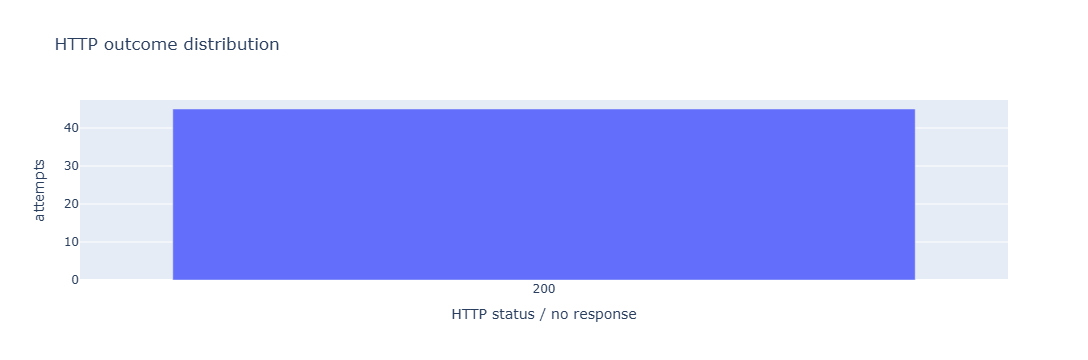

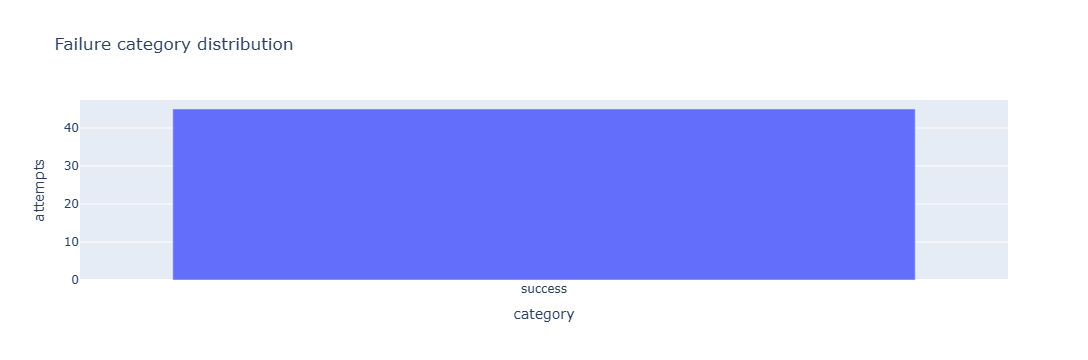

In [17]:
if not df.empty:
    outcome = df["status_code"].fillna("No HTTP response").astype(str).value_counts().rename_axis("HTTP status / no response").reset_index(name="attempts")
    px.bar(outcome, x="HTTP status / no response", y="attempts", title="HTTP outcome distribution").show()
    if "failure_category" in df:
        failure = df["failure_category"].fillna("success").value_counts().rename_axis("category").reset_index(name="attempts")
        px.bar(failure, x="category", y="attempts", title="Failure category distribution").show()


## 9. Rolling-median anomaly detection

In [18]:
demo = pd.Series([40, 42, 39, 41, 43, 40, 44, 42, 160, 41, 43], dtype=float)
rolling = rolling_median_anomalies(demo, window_size=5, min_observations=3, sensitivity=2.5)
display(pd.concat([demo.rename("latency_ms"), rolling.drop(columns="value")], axis=1))


,latency_ms,baseline,threshold,is_anomaly
0,40.0,NaN,NaN,False
1,42.0,NaN,NaN,False
2,39.0,NaN,NaN,False
3,41.0,40.0,NaN,True
4,43.0,40.5,NaN,True
5,40.0,41.0,43.5,False
6,44.0,41.0,43.5,True
7,42.0,41.0,43.5,False
8,160.0,42.0,44.5,True
9,41.0,43.0,48.0,False


## 10. IQR anomaly detection

In [19]:
iqr = iqr_anomalies(demo, k=1.5)
display(pd.concat([demo.rename("latency_ms"), iqr.drop(columns="value")], axis=1))


,latency_ms,q1,q3,iqr,lower_bound,upper_bound,is_anomaly
0,40.0,40.5,43.0,2.5,36.75,46.75,False
1,42.0,40.5,43.0,2.5,36.75,46.75,False
2,39.0,40.5,43.0,2.5,36.75,46.75,False
3,41.0,40.5,43.0,2.5,36.75,46.75,False
4,43.0,40.5,43.0,2.5,36.75,46.75,False
5,40.0,40.5,43.0,2.5,36.75,46.75,False
6,44.0,40.5,43.0,2.5,36.75,46.75,False
7,42.0,40.5,43.0,2.5,36.75,46.75,False
8,160.0,40.5,43.0,2.5,36.75,46.75,True
9,41.0,40.5,43.0,2.5,36.75,46.75,False


## 11. Synthetic spike experiment with ground truth

{'data': 'synthetic with injected spikes', 'TP': 3, 'FP': 0, 'FN': 0, 'precision': 1.0, 'recall': 1.0}


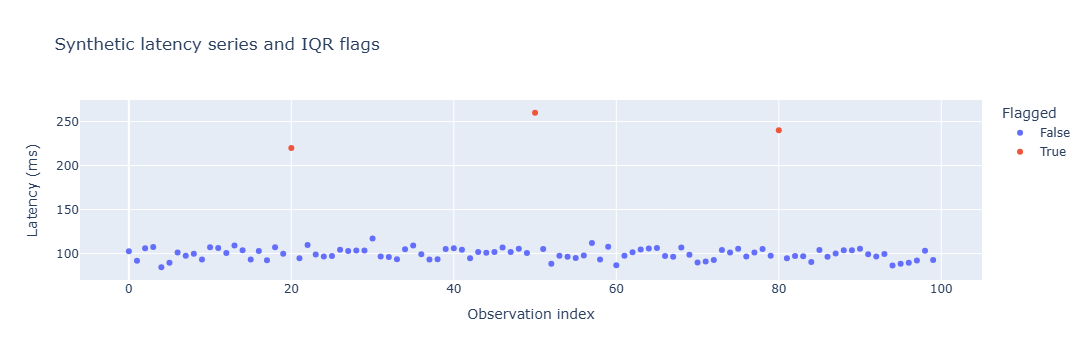

In [20]:
rng = np.random.default_rng(RANDOM_SEED)
normal = rng.normal(100, 8, 100).clip(1)
spike_positions = np.array([20, 50, 80])
synthetic_latency = normal.copy()
synthetic_latency[spike_positions] = [220, 260, 240]
ground_truth = np.zeros(len(synthetic_latency), dtype=bool)
ground_truth[spike_positions] = True
pred = iqr_anomalies(synthetic_latency, k=1.5)["is_anomaly"].to_numpy()
tp = int((pred & ground_truth).sum()); fp = int((pred & ~ground_truth).sum()); fn = int((~pred & ground_truth).sum())
precision = tp/(tp+fp) if tp+fp else None
recall = tp/(tp+fn) if tp+fn else None
print({"data":"synthetic with injected spikes", "TP":tp,"FP":fp,"FN":fn,"precision":precision,"recall":recall})
px.scatter(x=np.arange(len(synthetic_latency)), y=synthetic_latency, color=pred,
           title="Synthetic latency series and IQR flags", labels={"x":"Observation index","y":"Latency (ms)","color":"Flagged"}).show()


## 12. Sequential versus concurrent experiment methodology

In [21]:
print("For a real local measurement, start the local test API in another terminal:")
print("python scripts/run_local_test_server.py")
print("Then run: python scripts/run_experiments.py")
print("The script writes actual runtime results to outputs/experiment_results.json.")
print("This notebook does not invent a benchmark value; use the recorded output for your report.")


For a real local measurement, start the local test API in another terminal:
python scripts/run_local_test_server.py
Then run: python scripts/run_experiments.py
The script writes actual runtime results to outputs/experiment_results.json.
This notebook does not invent a benchmark value; use the recorded output for your report.


## 13. Results and discussion

In [22]:
if not df.empty:
    print("Source:", data_source)
    print("Observations:", len(df))
    print("Success rate (%):", round(100*df["success"].mean(), 2))
    print("Median latency (ms):", df["response_time_ms"].median())
    print("Interpret these as sample observations only; synthetic fallback data is not evidence about real services.")


Source: REAL local SQLite monitoring records
Observations: 45
Success rate (%): 100.0
Median latency (ms): 578.0000000377186
Interpret these as sample observations only; synthetic fallback data is not evidence about real services.


## 14. Limitations, conclusion, and future enhancements

A short observation period cannot establish long-term uptime. Rolling-median and IQR rules are explainable but may miss seasonality or drift. Synthetic observations demonstrate code paths only. Future work could include scheduled monitoring, alerting, robust network-level egress restrictions, and more advanced baselines after collecting a larger dataset.
